In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from IPython.display import display

# Directory containing the .dat files. Use Path('.') for the current directory.
DATA_DIR = Path("dat")

# Original file naming convention from Analise_1_e_2_RS.plt
VOLTAGE_PREFIX = (
    "HH_V_RS_gM0.070e-3_gL0.100e-3_gT0.000e-3_I"
)
FREQUENCY_FILE = (
    "HH_Freq_RS_gM0.070e-3_gL0.100e-3_gT0.000e-3_I0.000.dat"
)

# Three voltage traces, distributed across the original current range.
VOLTAGE_CURRENTS = ["0.500", "0.700", "0.900"]

# Figure output names
OUTPUT_STEM = "RS_Composite_Publication_Figure"

# Publication-oriented Matplotlib defaults
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "axes.linewidth": 1.0,
    "lines.linewidth": 1.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

In [3]:
voltage_files = {
    current: DATA_DIR / f"{VOLTAGE_PREFIX}{current}.dat"
    for current in VOLTAGE_CURRENTS
}
frequency_path = DATA_DIR / FREQUENCY_FILE

print("Voltage files:")
for current, path in voltage_files.items():
    print(f"  I = {current} nA: {path}")

print(f"Frequency file: {frequency_path}")

missing = [str(p) for p in [*voltage_files.values(), frequency_path] if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "The following required .dat files were not found:\\n"
        + "\\n".join(missing)
        + "\\n\\nSet DATA_DIR to the directory containing the data files."
    )

Voltage files:
  I = 0.500 nA: dat/HH_V_RS_gM0.070e-3_gL0.100e-3_gT0.000e-3_I0.500.dat
  I = 0.700 nA: dat/HH_V_RS_gM0.070e-3_gL0.100e-3_gT0.000e-3_I0.700.dat
  I = 0.900 nA: dat/HH_V_RS_gM0.070e-3_gL0.100e-3_gT0.000e-3_I0.900.dat
Frequency file: dat/HH_Freq_RS_gM0.070e-3_gL0.100e-3_gT0.000e-3_I0.000.dat


In [8]:
def read_dat(path):
    # Read whitespace-delimited numeric data; '#' comment lines are ignored.
    data = pd.read_csv(
        path,
        sep=" ",
        comment="#",
        header=None,
        engine="python",
    )
    data = data.apply(pd.to_numeric, errors="coerce").dropna(how="all")
    return data

voltage_data = {}
for current, path in voltage_files.items():
    df = read_dat(path)
    if df.shape[1] < 2:
        raise ValueError(f"{path.name} must contain at least 2 columns.")
    voltage_data[current] = df.iloc[:, :2].copy()
    voltage_data[current].columns = ["time_ms", "voltage_mV"]

frequency_data = read_dat(frequency_path)
if frequency_data.shape[1] < 11:
    raise ValueError(
        f"{frequency_path.name} has {frequency_data.shape[1]} columns; "
        "11 columns are required (current + F1...F10)."
    )

frequency_data = frequency_data.iloc[:, :11].copy()
frequency_data.columns = ["current_pA"] + [f"F{i}" for i in range(1, 11)]



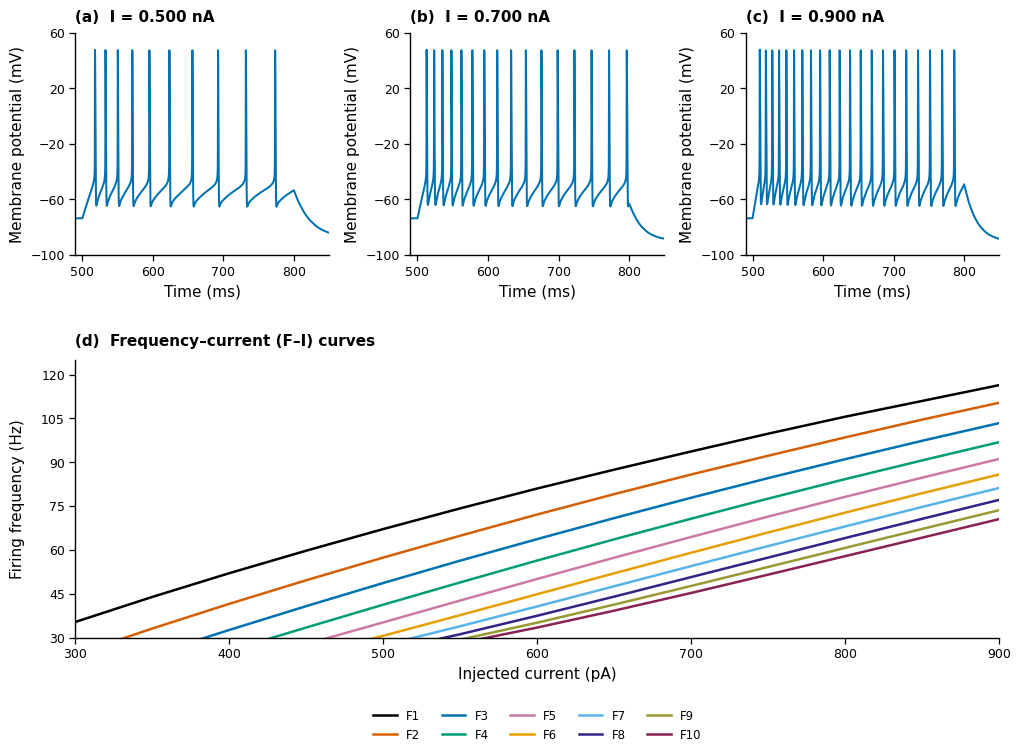

In [9]:
# Colorblind-friendly palette (Okabe–Ito-inspired)
voltage_color = "#0072B2"
fi_colors = [
    "#000000", "#D55E00", "#0072B2", "#009E73", "#CC79A7",
    "#E69F00", "#56B4E9", "#332288", "#999933", "#882255",
]

fig = plt.figure(figsize=(10.5, 7.2), constrained_layout=False)
gs = GridSpec(
    nrows=2,
    ncols=3,
    figure=fig,
    height_ratios=[1.0, 1.25],
    hspace=0.42,
    wspace=0.32,
    left=0.09,
    right=0.97,
    bottom=0.10,
    top=0.94,
)

panel_labels = ["(a)", "(b)", "(c)"]
voltage_axes = []

for idx, current in enumerate(VOLTAGE_CURRENTS):
    ax = fig.add_subplot(gs[0, idx])
    voltage_axes.append(ax)

    df = voltage_data[current]
    ax.plot(
        df["time_ms"],
        df["voltage_mV"],
        color=voltage_color,
        linewidth=1.45,
        solid_capstyle="round",
    )

    ax.set_title(f"{panel_labels[idx]}  I = {current} nA", loc="left", pad=8, weight="bold")
    ax.set_xlim(490, 850)
    ax.set_ylim(-100, 60)
    ax.set_xticks(np.arange(500, 851, 100))
    ax.set_yticks(np.arange(-100, 61, 40))
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Membrane potential (mV)")
    ax.tick_params(direction="out", length=4, width=0.9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# F-I panel spans the complete bottom row.
ax_fi = fig.add_subplot(gs[1, :])
for i, column in enumerate([f"F{k}" for k in range(1, 11)]):
    y = frequency_data[column].where(frequency_data[column] > 0, np.nan)
    ax_fi.plot(
        frequency_data["current_pA"],
        y,
        color=fi_colors[i],
        linewidth=1.8,
        label=column,
    )

ax_fi.set_title("(d)  Frequency–current (F–I) curves", loc="left", pad=10, weight="bold")
ax_fi.set_xlim(300, 900)
ax_fi.set_ylim(30, 125)
ax_fi.set_xticks(np.arange(300, 901, 100))
ax_fi.set_yticks(np.arange(30, 126, 15))
ax_fi.set_xlabel("Injected current (pA)")
ax_fi.set_ylabel("Firing frequency (Hz)")
ax_fi.tick_params(direction="out", length=4, width=0.9)
ax_fi.spines["top"].set_visible(False)
ax_fi.spines["right"].set_visible(False)

ax_fi.legend(
    ncol=5,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    handlelength=2.0,
    columnspacing=1.8,
)

fig.align_ylabels(voltage_axes + [ax_fi])
plt.show()